# Voice Cloning System
**voice cloning using Coqui XTTS-v2 — on Google Colab**

---

---
## SETUP CELL (Run Once per Session)

In [ ]:
# STEP 1 — Verify GPU and Python version
import sys
import torch

print("Python version:", sys.version)
print()

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("   CUDA:", torch.version.cuda, " | PyTorch:", torch.__version__)
else:
    print("NO GPU DETECTED!")
    print("Runtime → Change Runtime Type → T4 GPU")

major, minor = sys.version_info[:2]
if major == 3 and minor >= 10:
    print(f"Python {major}.{minor} is compatible with coqui-tts")
else:
    print(f"Python {major}.{minor} — coqui-tts needs Python 3.10+")

print("IMPORTANT — Read before Step 2:")
print("   Step 2 installs packages, then AUTO-RESTARTS the runtime.")
print("   After restart, START FROM STEP 3 (skip Steps 1 and 2).")


🐍 Python version: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]

✅ GPU available: Tesla T4
   CUDA: 12.8  | PyTorch: 2.10.0+cu128
✅ Python 3.12 is compatible with coqui-tts
📌 IMPORTANT — Read before Step 2:
   Step 2 installs packages, then AUTO-RESTARTS the runtime.
   After restart, START FROM STEP 3 (skip Steps 1 and 2).


In [ ]:
# STEP 2 — Install coqui-tts + restart runtime
#
# After this cell finishes, the runtime restarts automatically.
# When it does: do not re-run this cell. Start from Step 3.
import subprocess, sys, os

print("Installing packages...")

cmds = [
    [sys.executable, "-m", "pip", "install", "-q",
     "numpy>=1.22.0,<2.0.0", "--force-reinstall", "--no-cache-dir"],
    [sys.executable, "-m", "pip", "install", "-q",
     "coqui-tts==0.26.0", "--no-cache-dir"],
    [sys.executable, "-m", "pip", "install", "-q",
     "librosa", "soundfile", "matplotlib", "gradio==4.44.1",
     "--no-cache-dir"],
]

all_ok = True
labels = ["numpy (pinned 1.x)", "coqui-tts==0.26.0", "librosa/soundfile/gradio"]
for cmd, label in zip(cmds, labels):
    print(f"⬇️  {label} ...", end="", flush=True)
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(" ❌")
        print(result.stderr[-2000:])
        all_ok = False
    else:
        print(" ✅")

if all_ok:
    print("All packages installed!")
    print("Restarting runtime to reload numpy...")
    print("After restart: skip this cell, run from Step 3.")
    import time; time.sleep(2)
    os.kill(os.getpid(), 9)  # Force-kill the kernel process — Colab auto-restarts it
else:
    print("One or more installs failed. Check errors above and re-run.")


📦 Installing packages (this takes ~3 min)...
⬇️  numpy (pinned 1.x) ... ✅
⬇️  coqui-tts==0.26.0 ... ✅
⬇️  librosa/soundfile/gradio ... ✅
✅ All packages installed!
🔄 Restarting runtime to reload numpy...
   → After restart: skip this cell, run from Step 3.


In [ ]:
# STEP 3 — Create project folder structure
import os

folders = [
    'voice-cloning/data/raw_audio',
    'voice-cloning/data/processed',
    'voice-cloning/outputs',
]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

print('Project structure ready:')
for f in folders:
    print(f'   📁 {f}/')
print('\nContinue to Step 4 →')

✅ Project structure ready:
   📁 voice-cloning/data/raw_audio/
   📁 voice-cloning/data/processed/
   📁 voice-cloning/outputs/

Continue to Step 4 →


---
## 🎤 STEP 4 — Upload Your Reference Audio

In [ ]:
# ══════════════════════════════════════════════════════
# STEP 4 — Upload reference audio
#   • 6–30 seconds of clean speech
#   • No background music or noise
#   • WAV or MP3 format recommended
#   • One speaker only

from google.colab import files
import shutil, os

print('📁 Upload your reference audio file.')
print('   Supported: .wav  .mp3  .flac  .ogg')
print('   Best results: 6–30 seconds of clean speech')
print()

uploaded = files.upload()

REFERENCE_FILE = None
for fname in uploaded:
    dest = f'voice-cloning/data/raw_audio/{fname}'
    shutil.copy(fname, dest)
    os.remove(fname)
    REFERENCE_FILE = dest
    size_kb = os.path.getsize(dest) // 1024
    print(f'✅ Saved: {dest}  ({size_kb} KB)')

if REFERENCE_FILE:
    print(f'\nREFERENCE_FILE = "{REFERENCE_FILE}"')
    print('Continue to Step 5 →')
else:
    print('❌ No file uploaded. Please run this cell again and upload a file.')

📁 Upload your reference audio file.
   Supported: .wav  .mp3  .flac  .ogg
   Best results: 6–30 seconds of clean speech



Saving WhatsApp-Audio-2026-03-11-at-10.13.06-PM.wav to WhatsApp-Audio-2026-03-11-at-10.13.06-PM (2).wav
✅ Saved: voice-cloning/data/raw_audio/WhatsApp-Audio-2026-03-11-at-10.13.06-PM (2).wav  (371 KB)

🎙️  REFERENCE_FILE = "voice-cloning/data/raw_audio/WhatsApp-Audio-2026-03-11-at-10.13.06-PM (2).wav"
Continue to Step 5 →


---
## 🧹 STEP 5 — Preprocess Audio

In [ ]:

# STEP 5 — Preprocess reference audio
# Converts to 22050 Hz mono, trims silence, normalizes

import os
import librosa
import soundfile as sf
import numpy as np

# Auto-detect uploaded file if REFERENCE_FILE not set
if 'REFERENCE_FILE' not in dir() or REFERENCE_FILE is None:
    raw_files = [f for f in os.listdir('voice-cloning/data/raw_audio') if not f.startswith('.')]
    if not raw_files:
        raise FileNotFoundError('❌ No audio found. Please run Step 4 first.')
    REFERENCE_FILE = f'voice-cloning/data/raw_audio/{raw_files[0]}'

CLEAN_FILE = 'voice-cloning/data/processed/reference_clean.wav'
SR = 22050  # XTTS-v2 target sample rate

print(f'📂 Input:  {REFERENCE_FILE}')
print(f'📂 Output: {CLEAN_FILE}')
print('\nPreprocessing...')

try:
    # Load and resample
    audio, sr = librosa.load(REFERENCE_FILE, sr=SR, mono=True)
    print(f'   ✅ Loaded: {len(audio)/SR:.2f}s  (original sr={sr}Hz)')

    # Trim silence from beginning and end
    audio_trimmed, _ = librosa.effects.trim(audio, top_db=20)
    print(f'   ✅ Trimmed: {len(audio_trimmed)/SR:.2f}s')

    if len(audio_trimmed) / SR < 3:
        print('   ⚠️  Warning: Audio is very short (<3s). Quality may be poor.')
        print('         Recommendation: use 6–30 seconds of clean speech.')

    # Peak-normalize to 0.95
    peak = np.max(np.abs(audio_trimmed))
    audio_norm = audio_trimmed / peak * 0.95 if peak > 0 else audio_trimmed

    # Save as 16-bit WAV
    sf.write(CLEAN_FILE, audio_norm, SR, subtype='PCM_16')
    size_kb = os.path.getsize(CLEAN_FILE) // 1024
    print(f'   ✅ Saved clean file: {CLEAN_FILE}  ({size_kb} KB)')
    print('\n✅ Preprocessing complete! Continue to Step 6 →')

except Exception as e:
    print(f'\n❌ Preprocessing failed: {e}')
    print('   → Check that the file is a valid audio file')
    print('   → Try converting to WAV first using Audacity or ffmpeg')
    raise

📂 Input:  voice-cloning/data/raw_audio/WhatsApp-Audio-2026-03-11-at-10.13.06-PM (2).wav
📂 Output: voice-cloning/data/processed/reference_clean.wav

⚙️  Preprocessing...
   ✅ Loaded: 3.96s  (original sr=22050Hz)
   ✅ Trimmed: 2.93s
   ⚠️  Warning: Audio is very short (<3s). Quality may be poor.
         Recommendation: use 6–30 seconds of clean speech.
   ✅ Saved clean file: voice-cloning/data/processed/reference_clean.wav  (126 KB)

✅ Preprocessing complete! Continue to Step 6 →


---
## 🤖 STEP 6 — Load XTTS-v2 Model & Clone Voice

In [ ]:
# First run downloads 1.8 GB — subsequent runs use cache.

import os, sys
import torch

# Quick dependency check before loading TTS
try:
    from transformers import BeamSearchScorer 
except ImportError:
    print("❌ transformers version is too new — BeamSearchScorer was removed.")
    print("   Fixing now (no restart needed)...")
    import subprocess
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "transformers==4.37.2", "--no-cache-dir"],
        check=True
    )
    print("   ✅ transformers pinned. Continuing...")

    import importlib
    for mod in list(sys.modules.keys()):
        if mod.startswith("transformers"):
            del sys.modules[mod]

os.environ["COQUI_TOS_AGREED"] = "1"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cpu":
    print("   ⚠️  CPU mode is very slow. Enable GPU for fast inference.")

print("Loading XTTS-v2 model (downloads ~1.8 GB on first run)...")
print("   Please wait — this may take 2–5 minutes on first run.")

from TTS.api import TTS
tts = TTS("tts_models/multilingual/multi-dataset/xtts_v2").to(device)

print("✅ Model loaded successfully!")
print("Continue to Step 6B →")


❌ transformers version is too new — BeamSearchScorer was removed.
   Fixing now (no restart needed)...
   ✅ transformers pinned. Continuing...
🖥️  Using device: cuda
📥 Loading XTTS-v2 model (downloads ~1.8 GB on first run)...
   Please wait — this may take 2–5 minutes on first run.


/usr/local/lib/python3.12/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.12/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.12/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")
100%|█████████▉| 1.87G/1.87G [00:33<00:00, 54.8MiB/s]
100%|██████████| 1.87G/1.87G [00:33<00:00, 55.5MiB/s]
4.37kiB [00:00, 29.0kiB/s]

361kiB [00:00, 2.55MiB/s]
100%|██████████| 32.0/32.0 [00:00<00:00, 128iB/s]
100%|██████████| 7.75M/7.75M [00:15<00:00, 4.12kiB/s]

✅ Model loaded successfully!
Continue to Step 6B →


In [ ]:
# STEP 6B — Synthesize cloned voice
#  Edit TEXT and LANGUAGE below before running!
import os
from IPython.display import Audio, display, HTML

# ── EDIT THESE ───────────────────────────────────────
TEXT = "Hello! Raimal, are you coming campus today?"
LANGUAGE = 'en'   # en | es | fr | de | it | pt | pl | tr | ru | nl | cs | ar | zh-cn | ja | hu | ko | hi
# ─────────────────────────────────────────────────────

CLEAN_FILE  = 'voice-cloning/data/processed/reference_clean.wav'
OUTPUT_FILE = 'voice-cloning/outputs/cloned_voice.wav'

if not os.path.exists(CLEAN_FILE):
    raise FileNotFoundError(f'Missing clean audio file. Please run Step 5 first.')

print(f'Language : {LANGUAGE}')
print(f'Text     : "{TEXT[:80]}..."' if len(TEXT) > 80 else f'📄 Text     : "{TEXT}"')
print(f'Reference: {CLEAN_FILE}')
print(f'Output   : {OUTPUT_FILE}')
print('\nSynthesizing... (10–30 seconds on T4 GPU)\n')

try:
    tts.tts_to_file(
        text=TEXT,
        speaker_wav=CLEAN_FILE,
        language=LANGUAGE,
        file_path=OUTPUT_FILE,
    )

    size_kb = os.path.getsize(OUTPUT_FILE) // 1024
    print(f'\n✅ Success! Output saved: {OUTPUT_FILE}  ({size_kb} KB)')
    print('\nPlaying cloned voice:')
    display(HTML('<h4 style="color:#06b6d4">🎙️ Cloned Voice Output:</h4>'))
    display(Audio(OUTPUT_FILE, autoplay=True))
    print('\nContinue to Step 7 →')

except Exception as e:
    print(f'\n❌ Synthesis failed: {e}')
    print('   → Make sure the model was loaded in Step 6A')
    print('   → Make sure CLEAN_FILE exists from Step 5')
    raise

🌍 Language : en
📄 Text     : "Hello! Raimal, are you coming campus today?"
🎤 Reference: voice-cloning/data/processed/reference_clean.wav
💾 Output   : voice-cloning/outputs/cloned_voice.wav

⚙️  Synthesizing... (10–30 seconds on T4 GPU)


✅ Success! Output saved: voice-cloning/outputs/cloned_voice.wav  (193 KB)

🎧 Playing cloned voice:



Continue to Step 7 →


---
## 🔊 STEP 7 — Play & Compare Audio

In [ ]:
# STEP 7 — Compare reference vs cloned voice

import os
from IPython.display import Audio, display, HTML

CLEAN_FILE  = 'voice-cloning/data/processed/reference_clean.wav'
OUTPUT_FILE = 'voice-cloning/outputs/cloned_voice.wav'

display(HTML('<h3 style="color:#7c3aed">🎤 Reference Voice (your uploaded audio)</h3>'))
if os.path.exists(CLEAN_FILE):
    display(Audio(CLEAN_FILE, autoplay=False))
else:
    print('❌ Reference not found — re-run Step 5')

display(HTML('<h3 style="color:#06b6d4">🎙️ Cloned Voice Output</h3>'))
if os.path.exists(OUTPUT_FILE):
    size_kb = os.path.getsize(OUTPUT_FILE) // 1024
    display(Audio(OUTPUT_FILE, autoplay=False))
    display(HTML(f'<p style="color:#888">File size: {size_kb} KB &nbsp;|&nbsp; Path: {OUTPUT_FILE}</p>'))
else:
    print('❌ Output not found — re-run Step 6')

---
## 📊 STEP 8 — Visualize Waveforms & Mel Spectrograms

⚙️  Generating visualizations...
✅ Plot saved to: voice-cloning/outputs/analysis.png

📊 Displaying:


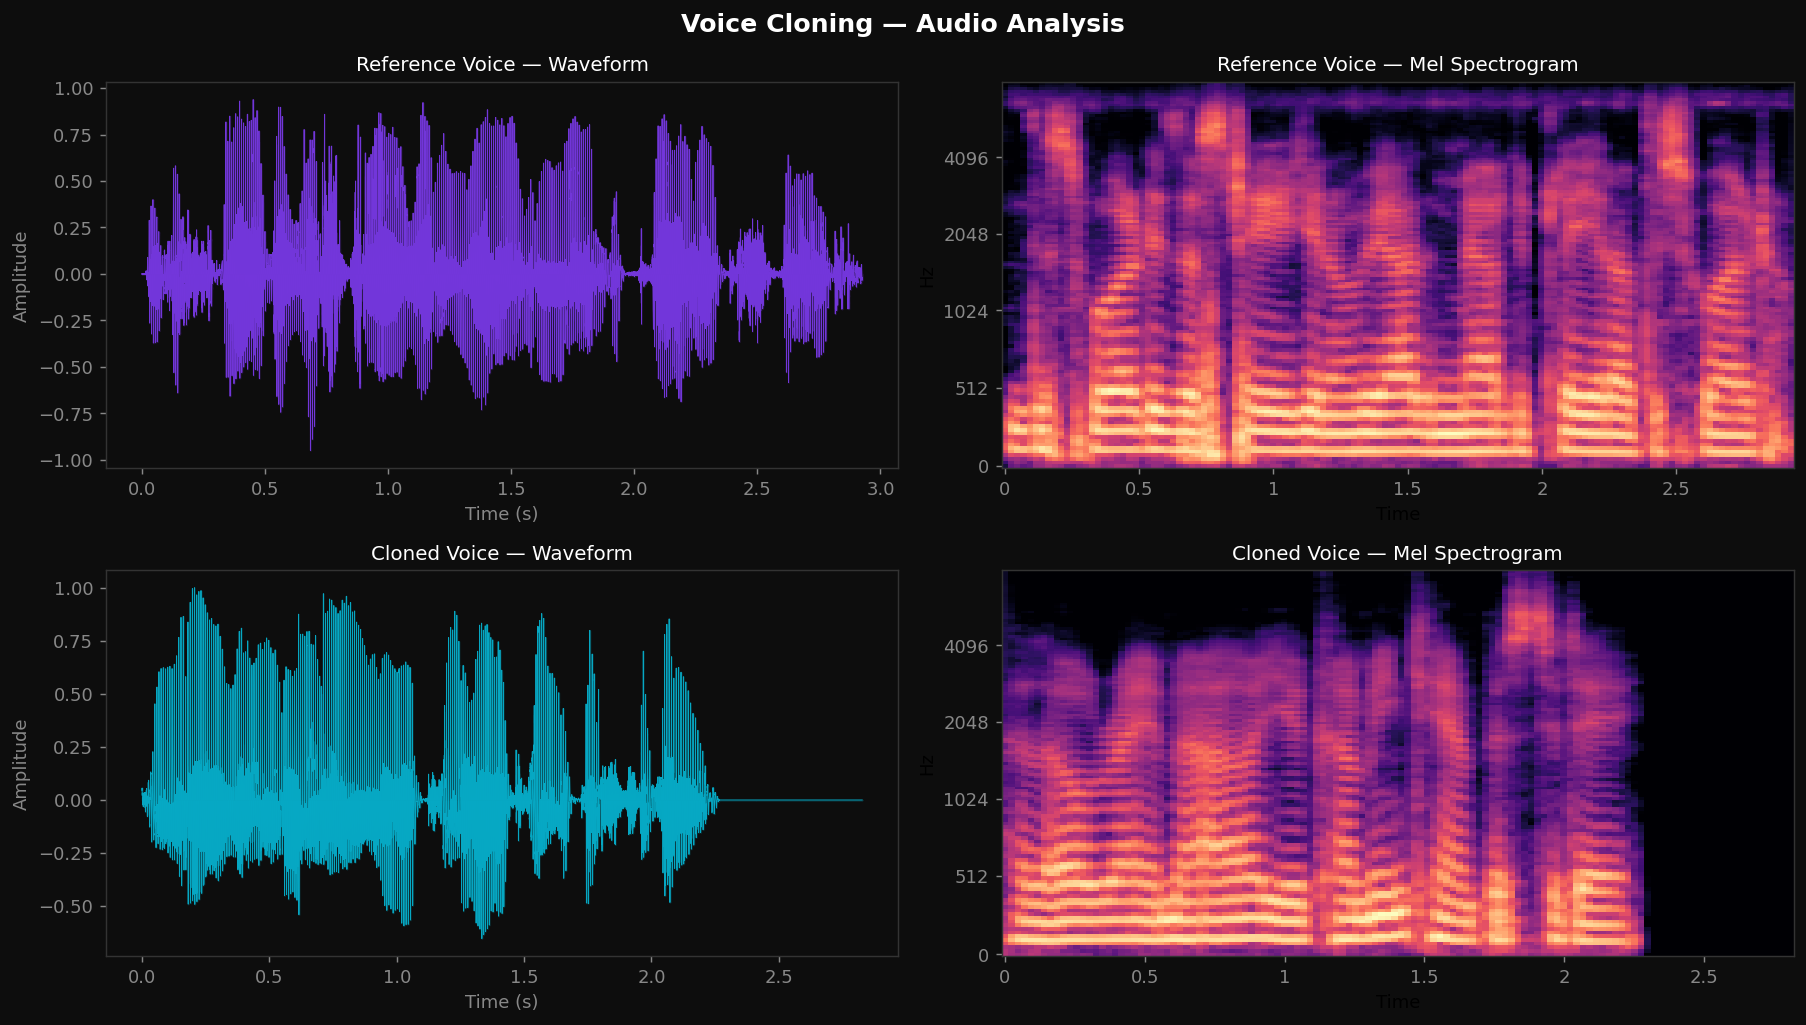

In [ ]:

# STEP 8 — Waveform + Mel Spectrogram comparison plot

import os
import librosa
import librosa.display
import numpy as np
import matplotlib
matplotlib.use('Agg')  # non-interactive backend for Colab
import matplotlib.pyplot as plt
from IPython.display import Image, display

CLEAN_FILE  = 'voice-cloning/data/processed/reference_clean.wav'
OUTPUT_FILE = 'voice-cloning/outputs/cloned_voice.wav'
PLOT_FILE   = 'voice-cloning/outputs/analysis.png'

for path, label in [(CLEAN_FILE, 'reference'), (OUTPUT_FILE, 'cloned')]:
    if not os.path.exists(path):
        raise FileNotFoundError(f'Missing {label} audio ({path}). Run Steps 5 and 6 first.')

print('⚙️  Generating visualizations...')

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle('Voice Cloning — Audio Analysis', color='white', fontsize=14, fontweight='bold')

pairs = [
    (CLEAN_FILE,  'Reference Voice', '#7c3aed'),
    (OUTPUT_FILE, 'Cloned Voice',    '#06b6d4'),
]

for i, (path, title, color) in enumerate(pairs):
    audio, sr = librosa.load(path, sr=22050)
    time_axis = np.linspace(0, len(audio) / sr, len(audio))

    # Waveform
    ax = axes[i][0]
    ax.set_facecolor('#0d0d0d')
    ax.plot(time_axis, audio, color=color, linewidth=0.5, alpha=0.9)
    ax.fill_between(time_axis, audio, alpha=0.15, color=color)
    ax.set_title(f'{title} — Waveform', color='white', fontsize=11)
    ax.set_xlabel('Time (s)', color='#888')
    ax.set_ylabel('Amplitude', color='#888')
    ax.tick_params(colors='#888')
    for spine in ax.spines.values():
        spine.set_edgecolor('#333')

    # Mel Spectrogram
    ax = axes[i][1]
    ax.set_facecolor('#0d0d0d')
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128, fmax=8000)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    librosa.display.specshow(mel_db, x_axis='time', y_axis='mel',
                             sr=sr, fmax=8000, ax=ax, cmap='magma')
    ax.set_title(f'{title} — Mel Spectrogram', color='white', fontsize=11)
    ax.tick_params(colors='#888')
    for spine in ax.spines.values():
        spine.set_edgecolor('#333')

plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=130, bbox_inches='tight', facecolor='#0d0d0d')
plt.close()

print(f'✅ Plot saved to: {PLOT_FILE}')
print('\n📊 Displaying:')
display(Image(PLOT_FILE))

---
## 💾 STEP 9 — Download Output Files

In [ ]:

# STEP 9 — Download cloned audio + analysis plot

from google.colab import files
import os

OUTPUT_FILE = 'voice-cloning/outputs/cloned_voice.wav'
PLOT_FILE   = 'voice-cloning/outputs/analysis.png'

if os.path.exists(OUTPUT_FILE):
    print('Downloading cloned voice audio...')
    files.download(OUTPUT_FILE)
    print('✅ cloned_voice.wav downloaded!')
else:
    print('❌ Output audio not found — run Step 6 first')

if os.path.exists(PLOT_FILE):
    print('\nDownloading analysis plot...')
    files.download(PLOT_FILE)
    print('✅ analysis.png downloaded!')
else:
    print('⚠️  Analysis plot not found — run Step 8 first (optional)')

📥 Downloading cloned voice audio...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ cloned_voice.wav downloaded!

📥 Downloading analysis plot...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ analysis.png downloaded!


---
## 🔁 STEP 10 — Try Different Texts

In [9]:
# ══════════════════════════════════════════════════════
# STEP 10 — Clone again with different text
# Model is already loaded — this is very fast!
# ✏️  Edit NEW_TEXT and LANGUAGE then run
# ══════════════════════════════════════════════════════
import os
from IPython.display import Audio, display, HTML

# ── EDIT THESE ───────────────────────────────────────
NEW_TEXT = 'Raimal How are you today?'
LANGUAGE = 'en'   # en | es | fr | de | it | pt | pl | tr | ru | nl | cs | ar | zh-cn | ja | hu | ko | hi
# ─────────────────────────────────────────────────────

CLEAN_FILE = 'voice-cloning/data/processed/reference_clean.wav'
OUTPUT_NEW = 'voice-cloning/outputs/cloned_v2.wav'

if 'tts' not in dir():
    raise RuntimeError('Model not loaded! Run Step 6A first.')

print(f'🌍 Language : {LANGUAGE}')
print(f'📄 Text     : "{NEW_TEXT}"')
print('⚙️  Synthesizing...\n')

tts.tts_to_file(
    text=NEW_TEXT,
    speaker_wav=CLEAN_FILE,
    language=LANGUAGE,
    file_path=OUTPUT_NEW,
)

size_kb = os.path.getsize(OUTPUT_NEW) // 1024
print(f'✅ Saved: {OUTPUT_NEW}  ({size_kb} KB)')
display(HTML('<h4 style="color:#06b6d4">🎙️ New Cloned Output:</h4>'))
display(Audio(OUTPUT_NEW, autoplay=True))

🌍 Language : en
📄 Text     : "Raimal How are you today?"
⚙️  Synthesizing...

✅ Saved: voice-cloning/outputs/cloned_v2.wav  (117 KB)


---
## 🚀 BONUS — Interactive Gradio Web UI

In [ ]:
# You'll get a public shareable URL via share=True
# ⚠️  Keep this cell running — stopping it kills the app

import os
import gradio as gr
import torch
import librosa
import soundfile as sf
import numpy as np

os.makedirs('voice-cloning/outputs', exist_ok=True)
os.makedirs('voice-cloning/data/processed', exist_ok=True)

if 'tts' not in dir():
    raise RuntimeError('Model not loaded! Run Step 6A first, then run this cell.')

LANG_MAP = {
    'English': 'en', 'Spanish': 'es', 'French': 'fr', 'German': 'de',
    'Italian': 'it', 'Portuguese': 'pt', 'Polish': 'pl', 'Turkish': 'tr',
    'Russian': 'ru', 'Dutch': 'nl', 'Czech': 'cs', 'Arabic': 'ar',
    'Chinese': 'zh-cn', 'Japanese': 'ja', 'Korean': 'ko', 'Hindi': 'hi',
}

def clean_audio(input_path, output_path):
    audio, sr = librosa.load(input_path, sr=22050, mono=True)
    trimmed, _ = librosa.effects.trim(audio, top_db=20)
    peak = np.max(np.abs(trimmed))
    norm = trimmed / peak * 0.95 if peak > 0 else trimmed
    sf.write(output_path, norm, 22050, subtype='PCM_16')
    return output_path

def clone_voice(text, audio_file, language):
    if not text or not text.strip():
        return None, '❌ Please enter some text.'
    if audio_file is None:
        return None, '❌ Please upload a reference audio file.'
    if len(text) > 500:
        return None, '❌ Text too long (max 500 characters).'
    try:
        lang = LANG_MAP.get(language, 'en')
        clean = 'voice-cloning/data/processed/gradio_ref.wav'
        out   = f'voice-cloning/outputs/gradio_{abs(hash(text)) % 99999}.wav'
        clean_audio(audio_file, clean)
        tts.tts_to_file(text=text, speaker_wav=clean, language=lang, file_path=out)
        kb = os.path.getsize(out) // 1024
        return out, f'✅ Done! Language: {language} | Size: {kb} KB'
    except Exception as e:
        return None, f'❌ Error: {e}'

with gr.Blocks(title='Voice Cloning System', theme=gr.themes.Soft()) as demo:
    gr.Markdown('# 🎙️ Voice Cloning System\nPowered by Coqui XTTS-v2 | 17 Languages | Free on Colab')
    with gr.Row():
        with gr.Column():
            audio_in  = gr.Audio(label='Reference Voice (6–300 sec)', type='filepath')
            text_in   = gr.Textbox(
                label='Text to Synthesize (max 500 chars)',
                placeholder='Enter the text you want spoken in your cloned voice...',
                lines=4
            )
            lang_in   = gr.Dropdown(
                list(LANG_MAP.keys()),
                label='Language', value='English'
            )
            clone_btn = gr.Button('⚡ Clone Voice', variant='primary')
        with gr.Column():
            audio_out  = gr.Audio(label='Cloned Voice Output')
            status_out = gr.Textbox(label='Status', interactive=False)

    gr.Examples(
        examples=[
            ['Hello! This is my cloned voice speaking. Amazing, right?'],
            ['Artificial intelligence is transforming everything around us.'],
            ['Deep learning enables real-time voice synthesis at scale.'],
        ],
        inputs=[text_in]
    )

    clone_btn.click(
        fn=clone_voice,
        inputs=[text_in, audio_in, lang_in],
        outputs=[audio_out, status_out]
    )

print('🚀 Launching Gradio app...')
print('   A public URL will appear below (share=True)')
print('   ⚠️  Keep this cell running — stopping it kills the app\n')
demo.launch(share=True, server_port=7860)

ImportError: cannot import name 'HfFolder' from 'huggingface_hub' (/usr/local/lib/python3.12/dist-packages/huggingface_hub/__init__.py)